# **MMA3001 Project – Detection of Unusual VOC Events**

This project investigates whether environmental sensor measurements can be used
to identify unusually high volatile organic compound (VOC) events. Environmental variables and temporal features are analysed, and classification models are compared to evaluate their ability to detect these rare events.

---



# 1. Data Loading and Sensor Identification

In [35]:
import pandas as pd

# Load environmental sensor data
df = pd.read_csv(
    '/5EnvSensor_MayToDec2024_180kRows.csv',
    dtype={'sensorid': str}
)

# Load sensor location information
env = pd.read_excel(
    '/Sensor ID and Locations.xlsx',
    dtype={'ID': str}
)

print("Environmental dataset shape:", df.shape)
print("Sensor-location dataset shape:", env.shape)

Environmental dataset shape: (179447, 8)
Sensor-location dataset shape: (78, 6)


In [36]:
# Get the five sensor IDs in the dataset
sensor_ids = df['sensorid'].unique()

print("Number of sensors:", len(sensor_ids))
print("Sensor IDs:", sensor_ids)

# Match them with the location spreadsheet
matches = env[env['ID'].isin(sensor_ids)]

matches

Number of sensors: 5
Sensor IDs: ['6012002000241' '6012002000326' '6012002000777' '6012002000869'
 '6012002000227']


,Building,Floor/Room,Area,Physical Label,Sensor,ID
60,60,G.38,Compactus_upper,EMS107,Env,6012002000869


Five unique sensor IDs were identified in the environmental dataset. When matched against the provided sensor-location metadata, only one sensor had a corresponding location entry. Therefore, location information was not used as a criterion for selecting the sensor for further analysis.

# 2. Data Preprocessing

The environmental sensor measurements are stored within the jsondata column. The JSON data are extracted into separate numerical variables and combined with the corresponding sensor ID and timestamp to create a structured dataset for analysis.

---



In [37]:
import json

sample = json.loads(df['jsondata'].iloc[0])

for item in sample:
    print(
        item['variable']['name'],
        "=",
        item['values'][0]['value'],
        item['variable']['unit']
    )

Battery = 4.1875 V
Carbon dioxide = 603 ppm
Humidity = 66 HR%
Formaldehyde = 6 µg/m3
Pressure = 1011 mb
Temperature = 23.8 °C
Light Volatile Organic Compounds = 14 ppb
Particulate matter 1 = 8 µg/m3
Particulate matter 4 = 9 µg/m3
Particulate matter 2.5 = 9 µg/m3
Particulate matter 10 = 9 µg/m3


In [38]:
# Function to extract sensor measurements from jsondata
def extract_measurements(json_string):
    data = json.loads(json_string)

    measurements = {}

    for item in data:
        name = item['variable']['name']

        # Some measurements may not contain a value
        if item.get('values') and 'value' in item['values'][0]:
            value = item['values'][0]['value']
        else:
            value = None

        measurements[name] = value

    return measurements

# Apply to every row
measurements = df['jsondata'].apply(extract_measurements)

# Convert extracted measurements into columns
measurements_df = pd.DataFrame(measurements.tolist())

measurements_df.head()

,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10
0,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
1,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
2,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0
4,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0


In [39]:
clean_df = pd.concat(
    [
        df[['sensorid', 'createdate']].reset_index(drop=True),
        measurements_df.reset_index(drop=True)
    ],
    axis=1
)

clean_df['createdate'] = pd.to_datetime(clean_df['createdate'], utc=True)

clean_df.head()

,sensorid,createdate,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10
0,6012002000241,2024-02-28 16:11:58.210358+00:00,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
1,6012002000241,2024-02-29 06:09:08.833822+00:00,4.1875,603,66,6.0,1011,23.8,14.0,8.0,9.0,9.0,9.0
2,6012002000326,2024-02-29 06:09:12.444245+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,6012002000777,2024-02-29 06:10:24.443407+00:00,4.1562,425,51,1.0,1015,18.8,71.0,1.0,3.0,3.0,4.0
4,6012002000869,2024-02-29 06:11:11.348578+00:00,4.1250,465,56,17.0,1010,24.3,0.0,2.0,2.0,2.0,2.0


In [40]:
print("Shape:", clean_df.shape)

print("\nDate range:")
print(clean_df['createdate'].min())
print(clean_df['createdate'].max())

print("\nRows per sensor:")
print(clean_df['sensorid'].value_counts())

print("\nMissing values:")
print(clean_df.isna().sum())

Shape: (179447, 13)

Date range:
2024-02-28 16:11:58.210358+00:00
2026-04-22 13:20:33.199878+00:00

Rows per sensor:
sensorid
6012002000326    58909
6012002000241    58908
6012002000869    29341
6012002000227    21363
6012002000777    10926
Name: count, dtype: int64

Missing values:
sensorid                                 0
createdate                               0
Battery                                  0
Carbon dioxide                           0
Humidity                                 0
Formaldehyde                        113380
Pressure                                 0
Temperature                              0
Light Volatile Organic Compounds     29566
Particulate matter 1                  1709
Particulate matter 4                  1709
Particulate matter 2.5                1709
Particulate matter 10                 1709
dtype: int64


The JSON sensor measurements were extracted into separate numerical columns and combined with the corresponding sensor ID and timestamp. The resulting dataset was checked for its date range, number of observations per sensor and missing values before sensor selection and further analysis.

# 3. Sensor Data Exploration and Selection

In [41]:
clean_df.groupby('sensorid')['createdate'].agg(['min', 'max', 'count'])

,min,max,count
sensorid,,,
6012002000227,2024-04-30 14:08:47.303613+00:00,2024-10-10 04:55:44.036588+00:00,21363
6012002000241,2024-02-28 16:11:58.210358+00:00,2026-04-22 13:20:32.020253+00:00,58908
6012002000326,2024-02-29 06:09:12.444245+00:00,2026-04-22 13:20:33.199878+00:00,58909
6012002000777,2024-02-29 06:10:24.443407+00:00,2024-05-22 14:13:48.760363+00:00,10926
6012002000869,2024-02-29 06:11:11.348578+00:00,2024-10-10 04:56:13.917171+00:00,29341


In [42]:
for sensor in sensor_ids:
    temp = clean_df[clean_df['sensorid'] == sensor].copy()
    temp = temp.sort_values('createdate')

    gaps = temp['createdate'].diff()

    print(sensor, "median gap =", gaps.median())

6012002000241 median gap = 0 days 00:10:40.922700
6012002000326 median gap = 0 days 00:10:40.924003500
6012002000777 median gap = 0 days 00:10:47.788815
6012002000869 median gap = 0 days 00:10:43.030676
6012002000227 median gap = 0 days 00:10:42.511599


In [43]:
variables = [
    'Carbon dioxide',
    'Humidity',
    'Formaldehyde',
    'Pressure',
    'Temperature',
    'Light Volatile Organic Compounds',
    'Particulate matter 1',
    'Particulate matter 4',
    'Particulate matter 2.5',
    'Particulate matter 10'
]

clean_df[variables].describe()

,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10
count,179447.000000,179447.000000,66067.000000,179447.000000,179447.000000,149881.000000,177738.000000,177738.000000,177738.000000,177738.000000
mean,517.359543,56.603437,12.190246,1013.971312,21.408552,15.093147,3.699907,4.415555,4.259157,4.491532
std,80.685200,11.363086,15.470887,5.601243,3.428958,71.692572,3.304426,3.824748,3.658492,3.842756
min,400.000000,17.000000,1.000000,988.000000,11.800000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,447.000000,45.000000,4.000000,1011.000000,18.800000,0.000000,1.000000,2.000000,2.000000,2.000000
50%,520.000000,59.000000,5.000000,1012.000000,23.800000,7.000000,3.000000,3.000000,3.000000,4.000000
75%,603.000000,68.000000,6.000000,1016.000000,23.800000,14.000000,6.000000,7.000000,6.000000,7.000000
max,1387.000000,84.000000,55.000000,1028.000000,37.500000,8051.000000,73.000000,163.000000,105.000000,190.000000


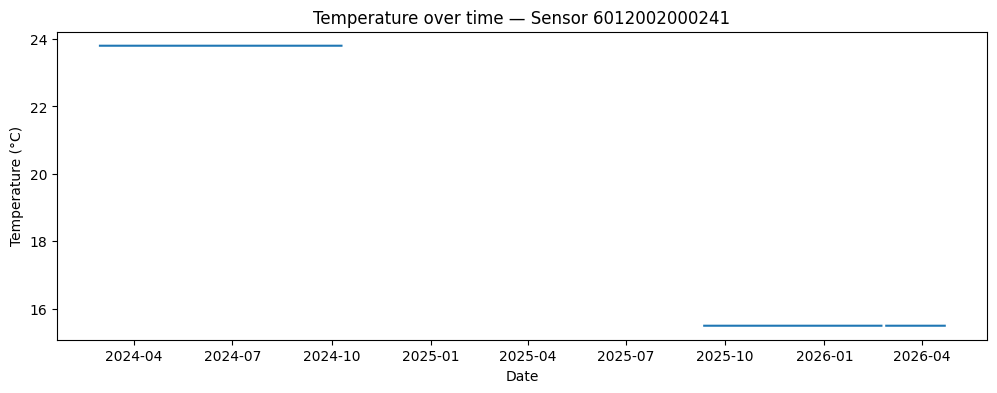

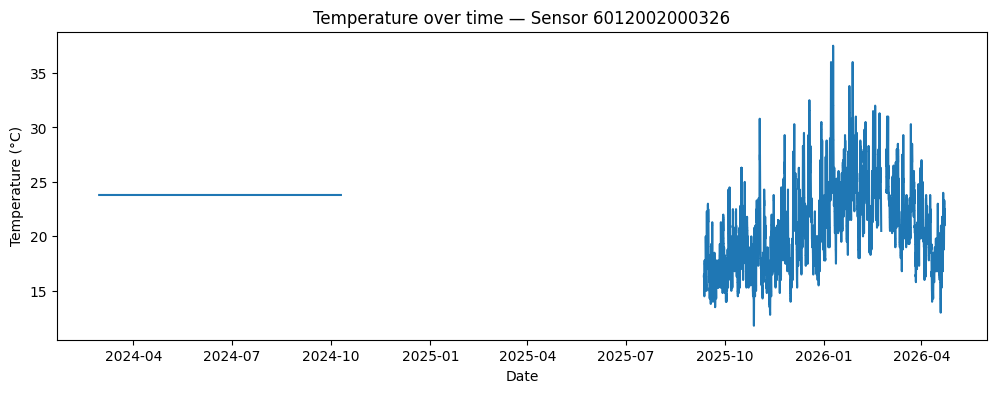

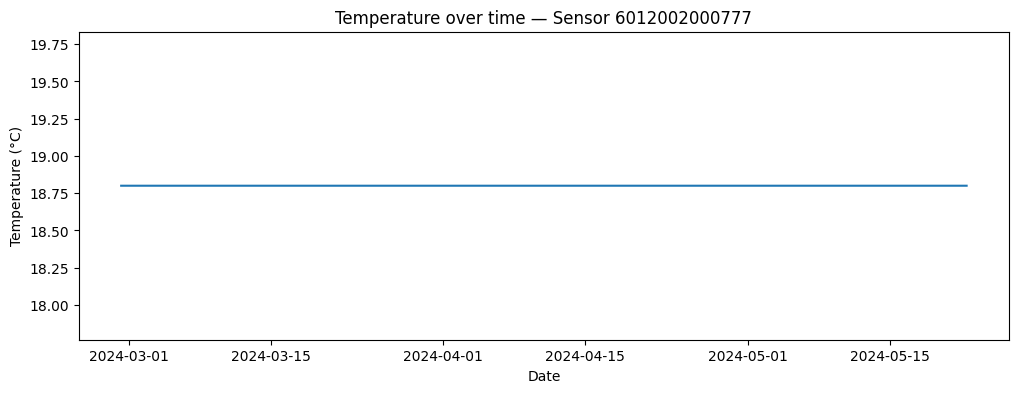

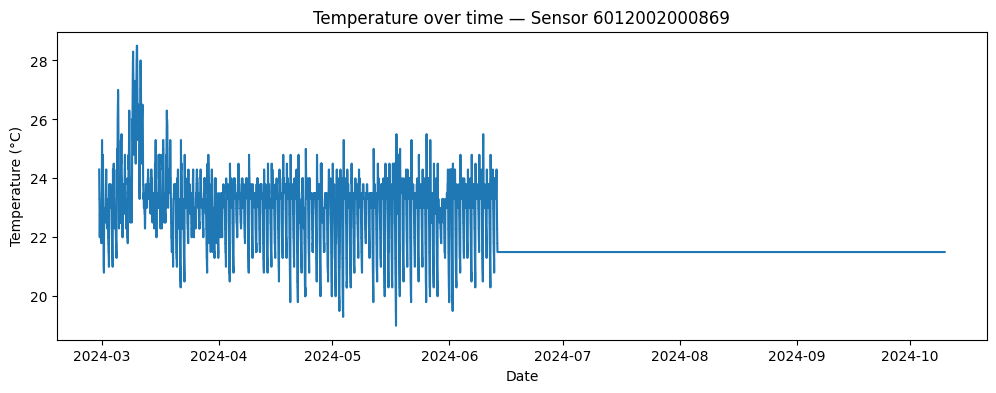

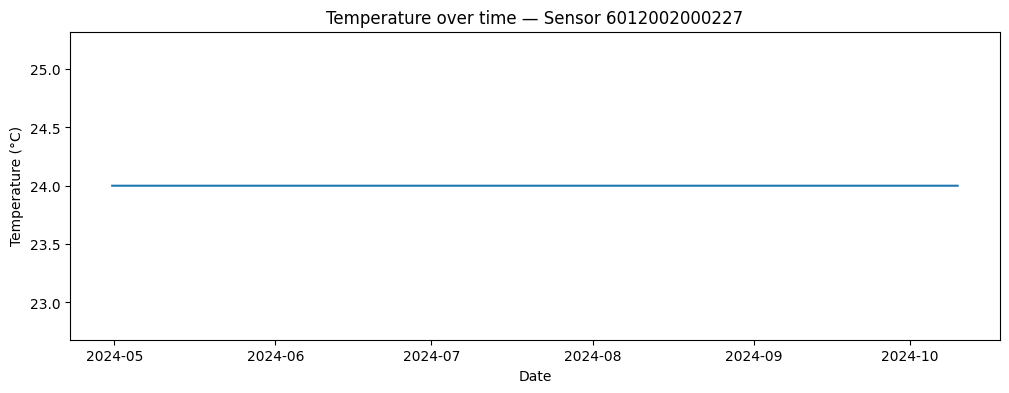

In [44]:
import matplotlib.pyplot as plt
import numpy as np

for sensor in sensor_ids:
    temp = clean_df[clean_df['sensorid'] == sensor].copy()
    temp = temp.sort_values('createdate')

    # Find gaps larger than 1 hour
    gaps = temp['createdate'].diff()

    # Break the plotted line after large gaps
    temp.loc[gaps > pd.Timedelta(hours=1), 'Temperature'] = np.nan

    plt.figure(figsize=(12, 4))
    plt.plot(temp['createdate'], temp['Temperature'])

    plt.xlabel('Date')
    plt.ylabel('Temperature (°C)')
    plt.title(f'Temperature over time — Sensor {sensor}')
    plt.show()

In [45]:
for sensor in sensor_ids:
    temp = clean_df[clean_df['sensorid'] == sensor]

    print("\nSensor:", sensor)

    for variable in variables:
        print(
            variable,
            "→ unique:",
            temp[variable].nunique()
        )


Sensor: 6012002000241
Carbon dioxide → unique: 2
Humidity → unique: 2
Formaldehyde → unique: 1
Pressure → unique: 2
Temperature → unique: 2
Light Volatile Organic Compounds → unique: 1
Particulate matter 1 → unique: 2
Particulate matter 4 → unique: 2
Particulate matter 2.5 → unique: 2
Particulate matter 10 → unique: 2

Sensor: 6012002000326
Carbon dioxide → unique: 245
Humidity → unique: 67
Formaldehyde → unique: 1
Pressure → unique: 37
Temperature → unique: 102
Light Volatile Organic Compounds → unique: 409
Particulate matter 1 → unique: 21
Particulate matter 4 → unique: 32
Particulate matter 2.5 → unique: 27
Particulate matter 10 → unique: 36

Sensor: 6012002000777
Carbon dioxide → unique: 1
Humidity → unique: 1
Formaldehyde → unique: 1
Pressure → unique: 1
Temperature → unique: 1
Light Volatile Organic Compounds → unique: 1
Particulate matter 1 → unique: 1
Particulate matter 4 → unique: 1
Particulate matter 2.5 → unique: 1
Particulate matter 10 → unique: 1

Sensor: 6012002000869
Ca

**Sensor selection**: Sensor 6012002000326 was selected for further analysis because it contained the largest number of observations and provided useful variation across the environmental measurements. Some other sensors contained fewer observations or measurements with very limited variation, which would provide less information for identifying unusual VOC behaviour.

In [46]:
sensor = '6012002000326'

good = clean_df[clean_df['sensorid'] == sensor].copy()
good = good.sort_values('createdate')

good[
    ['Temperature', 'Humidity', 'Carbon dioxide',
     'Pressure', 'Light Volatile Organic Compounds']
].describe()

,Temperature,Humidity,Carbon dioxide,Pressure,Light Volatile Organic Compounds
count,58909.000000,58909.000000,58909.000000,58909.000000,58909.000000
mean,22.305264,60.836833,482.809520,1010.368433,10.093619
std,3.154900,10.104586,45.739574,4.667555,110.096057
min,11.800000,17.000000,400.000000,988.000000,0.000000
25%,20.300000,54.000000,437.000000,1009.000000,0.000000
50%,23.800000,68.000000,525.000000,1012.000000,7.000000
75%,23.800000,68.000000,525.000000,1012.000000,7.000000
max,37.500000,84.000000,1387.000000,1024.000000,8051.000000


In [47]:
good.nlargest(20, 'Light Volatile Organic Compounds')[
    ['createdate',
     'Light Volatile Organic Compounds',
     'Temperature',
     'Humidity',
     'Carbon dioxide']
]

,createdate,Light Volatile Organic Compounds,Temperature,Humidity,Carbon dioxide
177778,2026-04-16 09:25:30.913293+00:00,8051.0,19.8,69,486
172104,2026-03-26 10:45:17.857454+00:00,5246.0,18.3,69,471
178076,2026-04-17 11:49:28.730583+00:00,5168.0,16.5,61,495
178876,2026-04-20 10:40:42.069894+00:00,4436.0,18.8,64,498
173996,2026-04-02 10:18:30.836611+00:00,4267.0,22.3,56,453
165582,2026-03-02 08:49:03.240673+00:00,4183.0,22.8,79,470
179152,2026-04-21 11:18:04.399715+00:00,4146.0,21.3,61,494
177234,2026-04-14 09:11:26.702843+00:00,3798.0,18.3,70,474
158204,2026-01-29 10:41:32.479835+00:00,3761.0,25.3,63,526
171272,2026-03-23 09:01:40.640910+00:00,3614.0,26.8,53,490


In [48]:
sensor = '6012002000326'

data = clean_df[clean_df['sensorid'] == sensor].copy()
data = data.sort_values('createdate').reset_index(drop=True)

print("Rows:", len(data))
print("Start:", data['createdate'].min())
print("End:", data['createdate'].max())

data.head()

Rows: 58909
Start: 2024-02-29 06:09:12.444245+00:00
End: 2026-04-22 13:20:33.199878+00:00


,sensorid,createdate,Battery,Carbon dioxide,Humidity,Formaldehyde,Pressure,Temperature,Light Volatile Organic Compounds,Particulate matter 1,Particulate matter 4,Particulate matter 2.5,Particulate matter 10
0,6012002000326,2024-02-29 06:09:12.444245+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
1,6012002000326,2024-02-29 06:22:37.635478+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
2,6012002000326,2024-02-29 06:36:02.083827+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
3,6012002000326,2024-02-29 06:49:28.824774+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0
4,6012002000326,2024-02-29 07:02:44.604671+00:00,4.1875,525,68,5.0,1012,23.8,7.0,6.0,6.0,6.0,6.0


In [49]:
data['time_gap'] = data['createdate'].diff()

large_gaps = data.loc[
    data['time_gap'] > pd.Timedelta(days=1),
    ['createdate', 'time_gap']
]

large_gaps

,createdate,time_gap
29342,2025-09-07 10:14:06.205114+00:00,332 days 05:18:19.530236
29344,2025-09-11 12:43:08.382587+00:00,4 days 02:28:37.312239
51563,2026-02-27 07:37:03.134979+00:00,4 days 11:45:11.442299


In [50]:
split_idx = data['time_gap'].idxmax()

before_gap = data.iloc[:split_idx].copy()
after_gap = data.iloc[split_idx:].copy()

print("BEFORE GAP")
print("Rows:", len(before_gap))
print("Start:", before_gap['createdate'].min())
print("End:", before_gap['createdate'].max())

print("\nAFTER GAP")
print("Rows:", len(after_gap))
print("Start:", after_gap['createdate'].min())
print("End:", after_gap['createdate'].max())

BEFORE GAP
Rows: 29342
Start: 2024-02-29 06:09:12.444245+00:00
End: 2024-10-10 04:55:46.674878+00:00

AFTER GAP
Rows: 29567
Start: 2025-09-07 10:14:06.205114+00:00
End: 2026-04-22 13:20:33.199878+00:00


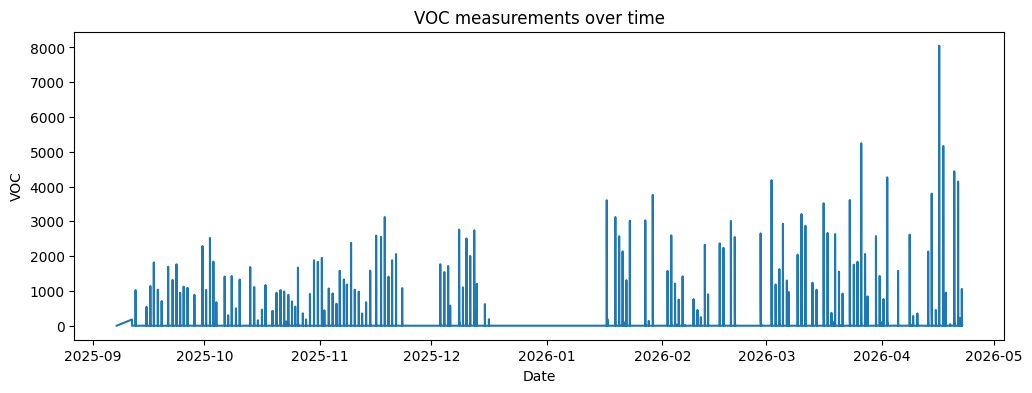

In [51]:
analysis_data = after_gap.copy()

plt.figure(figsize=(12, 4))
plt.plot(
    analysis_data['createdate'],
    analysis_data['Light Volatile Organic Compounds']
)

plt.xlabel('Date')
plt.ylabel('VOC')
plt.title('VOC measurements over time')
plt.show()

A large gap separates the selected sensor record into two disconnected periods. Treating observations across this gap as a continuous time series could distort temporal patterns. The post-gap period was therefore retained because it provides a single continuous and slightly larger, more recent block of observations for the subsequent VOC analysis.

In [52]:
print("Shape:", analysis_data.shape)

print("\nMissing values:")
print(analysis_data.isna().sum())

print("\nDuplicate rows:")
print(analysis_data.duplicated().sum())

print("\nDate range:")
print(analysis_data['createdate'].min())
print(analysis_data['createdate'].max())

Shape: (29567, 14)

Missing values:
sensorid                                0
createdate                              0
Battery                                 0
Carbon dioxide                          0
Humidity                                0
Formaldehyde                        29567
Pressure                                0
Temperature                             0
Light Volatile Organic Compounds        0
Particulate matter 1                 1709
Particulate matter 4                 1709
Particulate matter 2.5               1709
Particulate matter 10                1709
time_gap                                0
dtype: int64

Duplicate rows:
0

Date range:
2025-09-07 10:14:06.205114+00:00
2026-04-22 13:20:33.199878+00:00


Formaldehyde was excluded because it showed no useful variation in the selected sensor record and therefore would not provide discriminatory information for the analysis. time_gap was used only to identify discontinuities in the time series and was not required as an analysis feature.

In [53]:
work_data = analysis_data.drop(
    columns=['Formaldehyde', 'time_gap']
).copy()

print("Final working shape:", work_data.shape)
print("\nColumns:")
print(work_data.columns.tolist())

Final working shape: (29567, 12)

Columns:
['sensorid', 'createdate', 'Battery', 'Carbon dioxide', 'Humidity', 'Pressure', 'Temperature', 'Light Volatile Organic Compounds', 'Particulate matter 1', 'Particulate matter 4', 'Particulate matter 2.5', 'Particulate matter 10']


# 4. VOC Event Definition and Analysis

VOC measurements were first examined to determine how unusual events could be defined from the available data. Because many VOC readings were zero, the distribution of positive readings was examined separately so that the event threshold would represent unusually high measured VOC levels rather than being dominated by zero observations.

In [54]:
voc_nonzero = work_data.loc[
    work_data['Light Volatile Organic Compounds'] > 0,
    'Light Volatile Organic Compounds'
]

print("Non-zero VOC readings:", len(voc_nonzero))
print(voc_nonzero.describe())

print("\nPercentiles:")
print(voc_nonzero.quantile([0.50, 0.75, 0.90, 0.95, 0.99]))

Non-zero VOC readings: 914
count     914.000000
mean      425.832604
std       778.164103
min         2.000000
25%        21.000000
50%        86.000000
75%       462.750000
max      8051.000000
Name: Light Volatile Organic Compounds, dtype: float64

Percentiles:
0.50      86.00
0.75     462.75
0.90    1305.90
0.95    2014.35
0.99    3613.22
Name: Light Volatile Organic Compounds, dtype: float64


The 95th percentile of the non-zero VOC readings was selected as a data-driven threshold for defining a high-VOC event. Observations above this value are labelled as high_VOC = 1. This threshold is intended to identify unusual behaviour within this dataset and should not be interpreted as an established indoor-air-quality safety limit.

In [55]:
voc_threshold = voc_nonzero.quantile(0.95)

work_data['high_VOC'] = (
    work_data['Light Volatile Organic Compounds'] > voc_threshold
).astype(int)

print("VOC threshold:", voc_threshold)
print("\nHigh-VOC classification:")
print(work_data['high_VOC'].value_counts())

print("\nPercentage of ALL readings classified high VOC:")
print(work_data['high_VOC'].mean() * 100)

VOC threshold: 2014.349999999998

High-VOC classification:
high_VOC
0    29521
1       46
Name: count, dtype: int64

Percentage of ALL readings classified high VOC:
0.1555788548043427


Timestamps were converted from UTC to Melbourne local time so that high-VOC events could be investigated in relation to meaningful local hourly, daily and monthly patterns.

In [56]:
work_data['local_time'] = (
    work_data['createdate']
    .dt.tz_convert('Australia/Melbourne')
)

work_data['hour'] = work_data['local_time'].dt.hour
work_data['day_of_week'] = work_data['local_time'].dt.day_name()
work_data['month'] = work_data['local_time'].dt.month

In [57]:
hour_stats = work_data.groupby('hour').agg(
    total_readings=('high_VOC', 'count'),
    high_VOC_events=('high_VOC', 'sum')
)

hour_stats['event_rate_percent'] = (
    hour_stats['high_VOC_events'] /
    hour_stats['total_readings'] * 100
)

print("BY HOUR:")
print(hour_stats)


day_stats = work_data.groupby('day_of_week').agg(
    total_readings=('high_VOC', 'count'),
    high_VOC_events=('high_VOC', 'sum')
)

day_stats['event_rate_percent'] = (
    day_stats['high_VOC_events'] /
    day_stats['total_readings'] * 100
)

print("\nBY DAY:")
print(day_stats.sort_values('event_rate_percent', ascending=False))


month_stats = work_data.groupby('month').agg(
    total_readings=('high_VOC', 'count'),
    high_VOC_events=('high_VOC', 'sum')
)

month_stats['event_rate_percent'] = (
    month_stats['high_VOC_events'] /
    month_stats['total_readings'] * 100
)

print("\nBY MONTH:")
print(month_stats)

BY HOUR:
      total_readings  high_VOC_events  event_rate_percent
hour                                                     
0               1227                0            0.000000
1               1242                0            0.000000
2               1230                0            0.000000
3               1232                0            0.000000
4               1235                0            0.000000
5               1236                0            0.000000
6               1229                0            0.000000
7               1226                0            0.000000
8               1235                0            0.000000
9               1234                0            0.000000
10              1224                0            0.000000
11              1230                0            0.000000
12              1233                0            0.000000
13              1227                1            0.081500
14              1230                1            0.081301
15   

Event rates were calculated in addition to raw event counts because the number of observations differs between time periods. This allows temporal patterns to be compared without assuming that a period with more observations necessarily has a greater tendency for high-VOC events.

In [58]:
variables = [
    'Temperature',
    'Humidity',
    'Carbon dioxide',
    'Pressure',
    'Particulate matter 1',
    'Particulate matter 2.5',
    'Particulate matter 4',
    'Particulate matter 10'
]

comparison = work_data.groupby('high_VOC')[variables].mean().T

comparison.columns = ['Normal_VOC_mean', 'High_VOC_mean']

comparison['difference'] = (
    comparison['High_VOC_mean'] -
    comparison['Normal_VOC_mean']
)
comparison['percent_change'] = (
    (comparison['High_VOC_mean'] - comparison['Normal_VOC_mean'])
    / comparison['Normal_VOC_mean']
) * 100

comparison.round(2)

,Normal_VOC_mean,High_VOC_mean,difference,percent_change
Temperature,20.82,22.53,1.71,8.22
Humidity,53.73,55.67,1.95,3.63
Carbon dioxide,440.89,470.54,29.65,6.72
Pressure,1008.75,1009.78,1.03,0.10
Particulate matter 1,0.04,0.29,0.25,604.56
Particulate matter 2.5,0.06,0.40,0.34,547.06
Particulate matter 4,0.08,0.48,0.40,502.90
Particulate matter 10,0.09,0.52,0.44,499.60


Environmental variables were compared between normal and high-VOC observations to identify measurements associated with unusual VOC conditions. These differences are exploratory associations and do not establish that any individual variable causes the VOC events.

# 5. Classification Model Development

Classification models were developed to investigate whether high-VOC events could be identified using the other environmental measurements and time of day. The VOC measurement itself was excluded from the predictor variables because it was used to define the target label and including it would directly reveal whether an observation was classified as high VOC.

In [59]:
features = [
    'Temperature',
    'Humidity',
    'Carbon dioxide',
    'Pressure',
    'Particulate matter 1',
    'Particulate matter 2.5',
    'Particulate matter 4',
    'Particulate matter 10',
    'hour'
]

model_data = work_data[features + ['high_VOC']].dropna()

X = model_data[features]
y = model_data['high_VOC']

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nTarget counts:")
print(y.value_counts())

print("\nMissing values in X:")
print(X.isna().sum())

X shape: (27858, 9)
y shape: (27858,)

Target counts:
high_VOC
0    27816
1       42
Name: count, dtype: int64

Missing values in X:
Temperature               0
Humidity                  0
Carbon dioxide            0
Pressure                  0
Particulate matter 1      0
Particulate matter 2.5    0
Particulate matter 4      0
Particulate matter 10     0
hour                      0
dtype: int64


The data were divided into 80% training and 20% test sets. Stratification was used to preserve the very small proportion of high-VOC observations in both sets, and a fixed random state was used for reproducibility.

In [60]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("Rows:", len(y_train))
print(y_train.value_counts())

print("\nTest set:")
print("Rows:", len(y_test))
print(y_test.value_counts())

Training set:
Rows: 22286
high_VOC
0    22252
1       34
Name: count, dtype: int64

Test set:
Rows: 5572
high_VOC
0    5564
1       8
Name: count, dtype: int64


Three approaches were compared. A dummy classifier provides a no-skill baseline, while a decision tree can capture nonlinear relationships and remains relatively interpretable. Logistic regression provides a simpler linear classification alternative. Balanced class weights were used for the two trained classifiers because high-VOC events are extremely rare relative to normal observations.

In [61]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix, classification_report

baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_baseline,
    zero_division=0
))

Confusion matrix:
[[5564    0]
 [   8    0]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      5564
           1       0.00      0.00      0.00         8

    accuracy                           1.00      5572
   macro avg       0.50      0.50      0.50      5572
weighted avg       1.00      1.00      1.00      5572



In [62]:
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(
    max_depth=4,
    class_weight='balanced',
    random_state=42
)

tree.fit(X_train, y_train)

y_pred_tree = tree.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_tree,
    zero_division=0
))

Confusion matrix:
[[5348  216]
 [   4    4]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.96      0.98      5564
           1       0.02      0.50      0.04         8

    accuracy                           0.96      5572
   macro avg       0.51      0.73      0.51      5572
weighted avg       1.00      0.96      0.98      5572



In [63]:
importance = pd.Series(
    tree.feature_importances_,
    index=features
).sort_values(ascending=False)

print(importance)

hour                      6.381046e-01
Carbon dioxide            2.366174e-01
Temperature               5.636649e-02
Pressure                  3.717729e-02
Humidity                  3.173421e-02
Particulate matter 1      7.756136e-15
Particulate matter 10     2.580228e-15
Particulate matter 4      0.000000e+00
Particulate matter 2.5    0.000000e+00
dtype: float64


In [64]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

log_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight='balanced',
        random_state=42,
        max_iter=1000
    )
)

log_model.fit(X_train, y_train)

y_pred_log = log_model.predict(X_test)

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_log))

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred_log,
    zero_division=0
))

Confusion matrix:
[[4940  624]
 [   2    6]]

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.89      0.94      5564
           1       0.01      0.75      0.02         8

    accuracy                           0.89      5572
   macro avg       0.50      0.82      0.48      5572
weighted avg       1.00      0.89      0.94      5572



### Model Comparison




In [65]:
from sklearn.metrics import precision_score, recall_score, f1_score

def model_results(name, y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    return {
        'Model': name,
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred, zero_division=0),
        'F1 Score': f1_score(y_true, y_pred, zero_division=0),
        'True Positives': tp,
        'False Positives': fp,
        'False Negatives': fn
    }

results = pd.DataFrame([
    model_results('Dummy Baseline', y_test, y_pred_baseline),
    model_results('Decision Tree', y_test, y_pred_tree),
    model_results('Logistic Regression', y_test, y_pred_log)
])

results.round(3)

,Model,Precision,Recall,F1 Score,True Positives,False Positives,False Negatives
0,Dummy Baseline,0.000,0.00,0.000,0,0,8
1,Decision Tree,0.018,0.50,0.035,4,216,4
2,Logistic Regression,0.010,0.75,0.019,6,624,2


Three classification approaches were evaluated: a dummy baseline classifier, a decision tree classifier, and logistic regression.

The dummy classifier predicted all observations as normal and therefore failed to identify any high-VOC events. This demonstrates why overall accuracy is not an appropriate evaluation metric for this highly imbalanced dataset.

The decision tree identified 4 of the 8 high-VOC observations in the test set, corresponding to a recall of 0.50. Logistic regression identified 6 of the 8 high-VOC observations, giving a higher recall of 0.75. However, logistic regression also produced substantially more false-positive classifications.

These results demonstrate a trade-off between detecting unusual VOC events and generating false alarms. Since only 8 high-VOC observations were present in the test set, further evaluation is required before drawing strong conclusions about model performance.



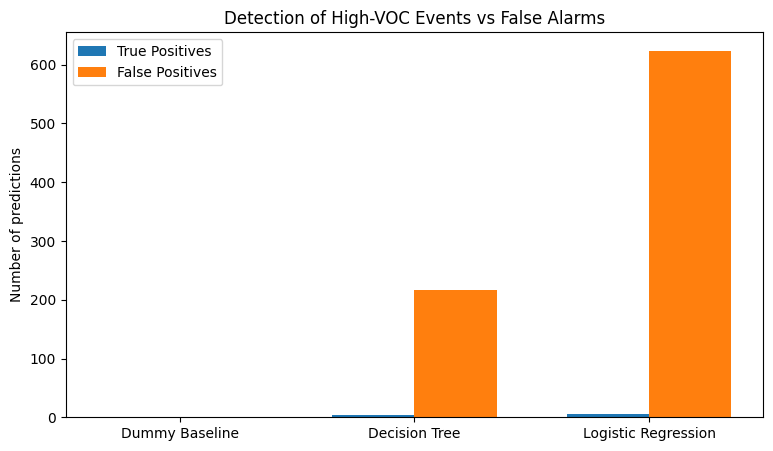

In [66]:
import matplotlib.pyplot as plt
import numpy as np

models = results['Model']
true_positives = results['True Positives']
false_positives = results['False Positives']
x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, true_positives, width, label='True Positives')
plt.bar(x + width/2, false_positives, width, label='False Positives')

plt.xticks(x, models)
plt.ylabel('Number of predictions')
plt.title('Detection of High-VOC Events vs False Alarms')
plt.legend()

plt.show()

Model Interpretation and Limitations
The results show that detecting rare high-VOC events is difficult because the dataset is highly imbalanced. Logistic regression detected 6 of the 8 high-VOC observations in the test set, compared with 4 detected by the decision tree, but this higher recall came at the cost of substantially more false positives: 624 compared with 216. From an engineering perspective, this represents a trade-off between detecting potentially unusual environmental conditions and generating unnecessary false alarms. Excessive false alarms could lead to unnecessary investigation or maintenance and reduce confidence in a monitoring system.

Within the decision tree, time of day and carbon dioxide were the most influential predictors, while the particulate-matter variables contributed little to the fitted model. These feature importances indicate which variables were most useful to this specific classifier, but they should not be interpreted as evidence of a causal relationship with VOC events.

The results should be interpreted cautiously because only 8 high-VOC observations were present in the test set, so the performance metrics are based on a very small number of unusual events. The analysis also uses data from only one environmental sensor, and the high-VOC threshold is data-driven rather than based on an established indoor-air-quality limit. In addition, the random train-test split does not explicitly account for temporal dependence between nearby sensor observations. Future work should therefore evaluate the method using additional sensors, longer time periods, alternative threshold definitions, and time-based or blocked validation before it is used for operational decision-making.